# AffectNet data perparation notebook

This dataset can be found in: https://mohammadmahoor.com/pages/databases/affectnet/ 

The data is structured as follows:
```text
AffectNet:
|---Manually_Annotated:
|---|---Manually_Annotated_Images
|---training.csv
|---validation.csv

We will convert it into an Images folder holding all the images and a labels.csv file.

In [1]:
import torchvision.transforms.v2 as v2
from torchvision.io import decode_image
import torch
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, shutil
import PIL.Image as Image
os.chdir('..')
from utility_scripts.adaface_utils.face_alignment.align import get_aligned_face

In [2]:
output_dir = os.path.join('data', 'datasets', 'emotion recognition', 'AffectNet')
os.path.exists(output_dir)

True

In [3]:
old_images_path = os.path.join(output_dir, 'Manually_Annotated', 'Manually_Annotated_Images')
os.path.exists(old_images_path)

True

In [4]:
new_images_path = os.path.join(output_dir, 'Images')
os.makedirs(new_images_path, exist_ok = True)

In [5]:
label_translation = {
    0 : 'neutral',
    1 : 'happy',
    2 : 'sad',
    3 : 'surprise',
    4 : 'fear',
    5 : 'disgust',
    6 : 'anger'
}

In [6]:
training_list = pd.read_csv(os.path.join(output_dir, 'training.csv'))
training_list['split'] = 'train'
validation_list = pd.read_csv(os.path.join(output_dir, 'validation.csv'))
validation_list['split'] = 'test'

combined_df = pd.concat([training_list, validation_list], ignore_index = True)

In [7]:
combined_df.head()

,subDirectory_filePath,face_x,face_y,face_width,face_height,facial_landmarks,expression,valence,arousal,split
0,689/737db2483489148d783ef278f43f486c0a97e140fc...,134.0,134.0,899,899,181.64;530.91;188.32;627.82;195.1;723.37;205.2...,1,0.785714,-0.055556,train
1,392/c4db2f9b7e4b422d14b6e038f0cdc3ecee239b5532...,20.0,20.0,137,137,28.82;77.52;29.12;93.25;31.04;108.51;33.03;123...,0,-0.017253,0.004313,train
2,468/21772b68dc8c2a11678c8739eca33adb6ccc658600...,11.0,11.0,176,176,30.52;87.33;32.55;106.43;36.94;125.81;43.06;14...,0,0.174603,0.007937,train
3,944/06e9ae8d3b240eb68fa60534783eacafce2def60a8...,40.0,40.0,269,269,44.43;158.17;47.08;189.2;50.54;221.88;58.3;253...,1,0.153401,0.038890,train
4,993/02e06ee5521958b4042dd73abb444220609d96f57b...,22.0,22.0,153,153,50.59;78.72;48.6;93.23;48.72;109.06;48.8;123.0...,8,0.783972,-0.551684,train


In [8]:
from utility_scripts.poster_v2_code.models.PosterV2_7cls import *
import numpy as np 
import torch.multiprocessing as mp

poster_model = get_poster_v2_model(os.path.join('data', 'models', 'poster_v2_models', 'affectnet-7-model_best.pth'))
poster_transform = v2.Compose([
    v2.Resize(size = (224, 224)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale = True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

poster_model.to('cuda')

/home/thoal/anaconda3/envs/pytorch/lib/python3.13/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/thoal/anaconda3/envs/pytorch/lib/python3.13/site-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


load_weight 304


/home/thoal/anaconda3/envs/pytorch/lib/python3.13/site-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


load_weight 747


pyramid_trans_expr2(
  (face_landback): MobileFaceNet(
    (conv1): Conv_block(
      (conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (prelu): PReLU(num_parameters=64)
    )
    (conv2_dw): Conv_block(
      (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (prelu): PReLU(num_parameters=64)
    )
    (conv_23): Depth_Wise(
      (conv): Conv_block(
        (conv): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (prelu): PReLU(num_parameters=128)
      )
      (conv_dw): Conv_block(
        (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=128, bias=False)
       

In [ ]:
new_image_names = []
expressions = []
splits = []
counter = 0
for i in range(len(combined_df)):
    expression = combined_df['expression'][i]
    if expression > 6:
        continue
    
    file_path = combined_df['subDirectory_filePath'][i]
    face_x = combined_df['face_x'][i]
    face_y = combined_df['face_y'][i]
    face_width = combined_df['face_width'][i]
    face_height = combined_df['face_height'][i]
    landmarks = combined_df['facial_landmarks'][i]
    split = combined_df['split'][i]
    try:
        image = Image.open(os.path.join(old_images_path, file_path))
    except:
        continue
    
    x1 = face_x
    x2 = face_x + face_width
    y1 = face_y
    y2 = face_y + face_height
    
    new_image_name = f'{counter}.jpg'
    
    try:
        aligned_image = get_aligned_face(image_path = None, rgb_pil_image = image)
        aligned_image.save(
            os.path.join(new_images_path, new_image_name)
        )
    except:
        aligned_image = image.crop(box = [x1, y1, x2, y2]).resize(size = (112, 112))
        aligned_image.save(
            os.path.join(new_images_path, new_image_name)
        )

    new_image_names.append(new_image_name)
    expressions.append(expression)
    splits.append(split)

    counter+=1

In [ ]:
labels_df = pd.DataFrame(
    data = {
        'filename' : new_image_names,
        'label' : expressions,
        'translated' : [label_translation[label] for label in expressions],
        'split' : splits 
    }
)

labels_df.to_csv(os.path.join(output_dir, 'labels.csv'), index = False)

In [9]:
labels_df = pd.read_csv(os.path.join(output_dir, 'labels.csv'))

In [10]:
poster_model.to('cuda')

pyramid_trans_expr2(
  (face_landback): MobileFaceNet(
    (conv1): Conv_block(
      (conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (prelu): PReLU(num_parameters=64)
    )
    (conv2_dw): Conv_block(
      (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (prelu): PReLU(num_parameters=64)
    )
    (conv_23): Depth_Wise(
      (conv): Conv_block(
        (conv): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (prelu): PReLU(num_parameters=128)
      )
      (conv_dw): Conv_block(
        (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=128, bias=False)
       

In [11]:
class AffectNet(torch.utils.data.Dataset):
    def __init__(self, labels_df, output_dir):
        self.labels_df = labels_df
        self.output_dir = output_dir
    
    def __len__(self):
        return len(self.labels_df)
    
    def __getitem__(self, idx):
        image = decode_image(os.path.join(self.output_dir, 'Images', self.labels_df['filename'].iloc[idx]))
        label = self.labels_df['label'].iloc[idx]

        return image, label

dataset = AffectNet(labels_df, output_dir)
dataloader = torch.utils.data.DataLoader(
    dataset, 
    batch_size = 768,
    shuffle = False,
    num_workers = 8,
)

total_batches = len(dataloader)
soft_labels = {str(i) : [] for i in range(7)}

with torch.no_grad():
    for i, batch in enumerate(dataloader):
        images, labels = batch
        images = images.to('cuda')
        images = poster_transform(images)
        
        output = poster_model(images)

        output = output.cpu().numpy()
        for j in range(7):
            soft_labels[str(j)].append(list(output[:, j]))
    
        print(i, total_batches)
    

0 375
1 375
2 375
3 375
4 375
5 375
6 375
7 375
8 375
9 375
10 375
11 375
12 375
13 375
14 375
15 375
16 375
17 375
18 375
19 375
20 375
21 375
22 375
23 375
24 375
25 375
26 375
27 375
28 375
29 375
30 375
31 375
32 375
33 375
34 375
35 375
36 375
37 375
38 375
39 375
40 375
41 375
42 375
43 375
44 375
45 375
46 375
47 375
48 375
49 375
50 375
51 375
52 375
53 375
54 375
55 375
56 375
57 375
58 375
59 375
60 375
61 375
62 375
63 375
64 375
65 375
66 375
67 375
68 375
69 375
70 375
71 375
72 375
73 375
74 375
75 375
76 375
77 375
78 375
79 375
80 375
81 375
82 375
83 375
84 375
85 375
86 375
87 375
88 375
89 375
90 375
91 375
92 375
93 375
94 375
95 375
96 375
97 375
98 375
99 375
100 375
101 375
102 375
103 375
104 375
105 375
106 375
107 375
108 375
109 375
110 375
111 375
112 375
113 375
114 375
115 375
116 375
117 375
118 375
119 375
120 375
121 375
122 375
123 375
124 375
125 375
126 375
127 375
128 375
129 375
130 375
131 375
132 375
133 375
134 375
135 375
136 375
137 375
138 37

In [15]:
new_soft_labels = {str(i) : [] for i in range(7)}

for i in range(7):
    new_soft_labels[str(i)] = np.concatenate(soft_labels[str(i)])

In [17]:
labels_df = pd.DataFrame(
    data = {
        'filename' : labels_df['filename'],
        'label' : labels_df['label'],
        **new_soft_labels,
        'translated' : labels_df['translated'],
        'split' : labels_df['split'] 
    }
)

labels_df.to_csv(os.path.join(output_dir, 'labels.csv'), index = False)

## EDA

In [4]:
labels_df = pd.read_csv(os.path.join(output_dir, 'labels.csv'))

In [5]:
len(labels_df)

287401

In [6]:
labels_df.head()

,filename,label,0,1,2,3,4,5,6,translated,split
0,0.jpg,1,1.091876,2.708592,-1.330207,-0.378613,-2.487576,0.515792,-0.092845,happy,train
1,1.jpg,0,2.653537,-0.753788,1.152170,0.895078,-1.124253,-3.945458,1.049861,neutral,train
2,2.jpg,0,2.669616,0.618775,2.074603,0.544825,-2.741639,-2.928225,0.038592,neutral,train
3,3.jpg,1,0.968598,0.924765,-1.457105,-0.654870,-1.865009,2.743226,-0.765349,happy,train
4,4.jpg,6,0.872191,-1.544016,-1.299899,2.705298,-0.751229,-1.325430,0.962422,anger,train


In [7]:
labels_df.tail()

,filename,label,0,1,2,3,4,5,6,translated,split
287396,287396.jpg,0,3.142272,-1.033516,1.151663,0.052225,-1.518865,-3.148289,1.346633,neutral,test
287397,287397.jpg,6,-0.936161,-2.948376,-0.424510,-1.334163,-0.723139,3.113264,3.174835,anger,test
287398,287398.jpg,6,1.299183,-1.993610,0.703178,-2.554248,-2.050310,1.049437,3.751263,anger,test
287399,287399.jpg,3,0.298008,-3.308523,1.171899,0.045402,1.895956,-1.968807,1.302535,surprise,test
287400,287400.jpg,2,-0.366186,-1.430735,3.627535,-3.219869,-1.559462,2.097442,1.162855,sad,test


In [8]:
np.unique(labels_df['split'], return_counts = True)

(array(['test', 'train'], dtype=object), array([  3500, 283901]))

In [9]:
classes, counts = np.unique(labels_df.label, return_counts = True)
sorted_idx = np.argsort(counts)
counts = counts[sorted_idx]
classes = classes[sorted_idx]

In [10]:
counts

array([  4303,   6878,  14590,  25382,  25959,  75374, 134915])

In [11]:
plt.figure(figsize = (8, 6), dpi = 600)
plt.bar([label_translation[cls] for cls in classes], counts)
plt.xlabel('Emotion', labelpad = 20)
plt.ylabel('Number of samples', labelpad = 15)
plt.savefig(
    os.path.join('data', 'figures', 'Emotion Recognition', 'AffectNet', 'The distribution of classes in AffectNet')
)
plt.show()


NameError: name 'label_translation' is not defined

<Figure size 4800x3600 with 0 Axes>

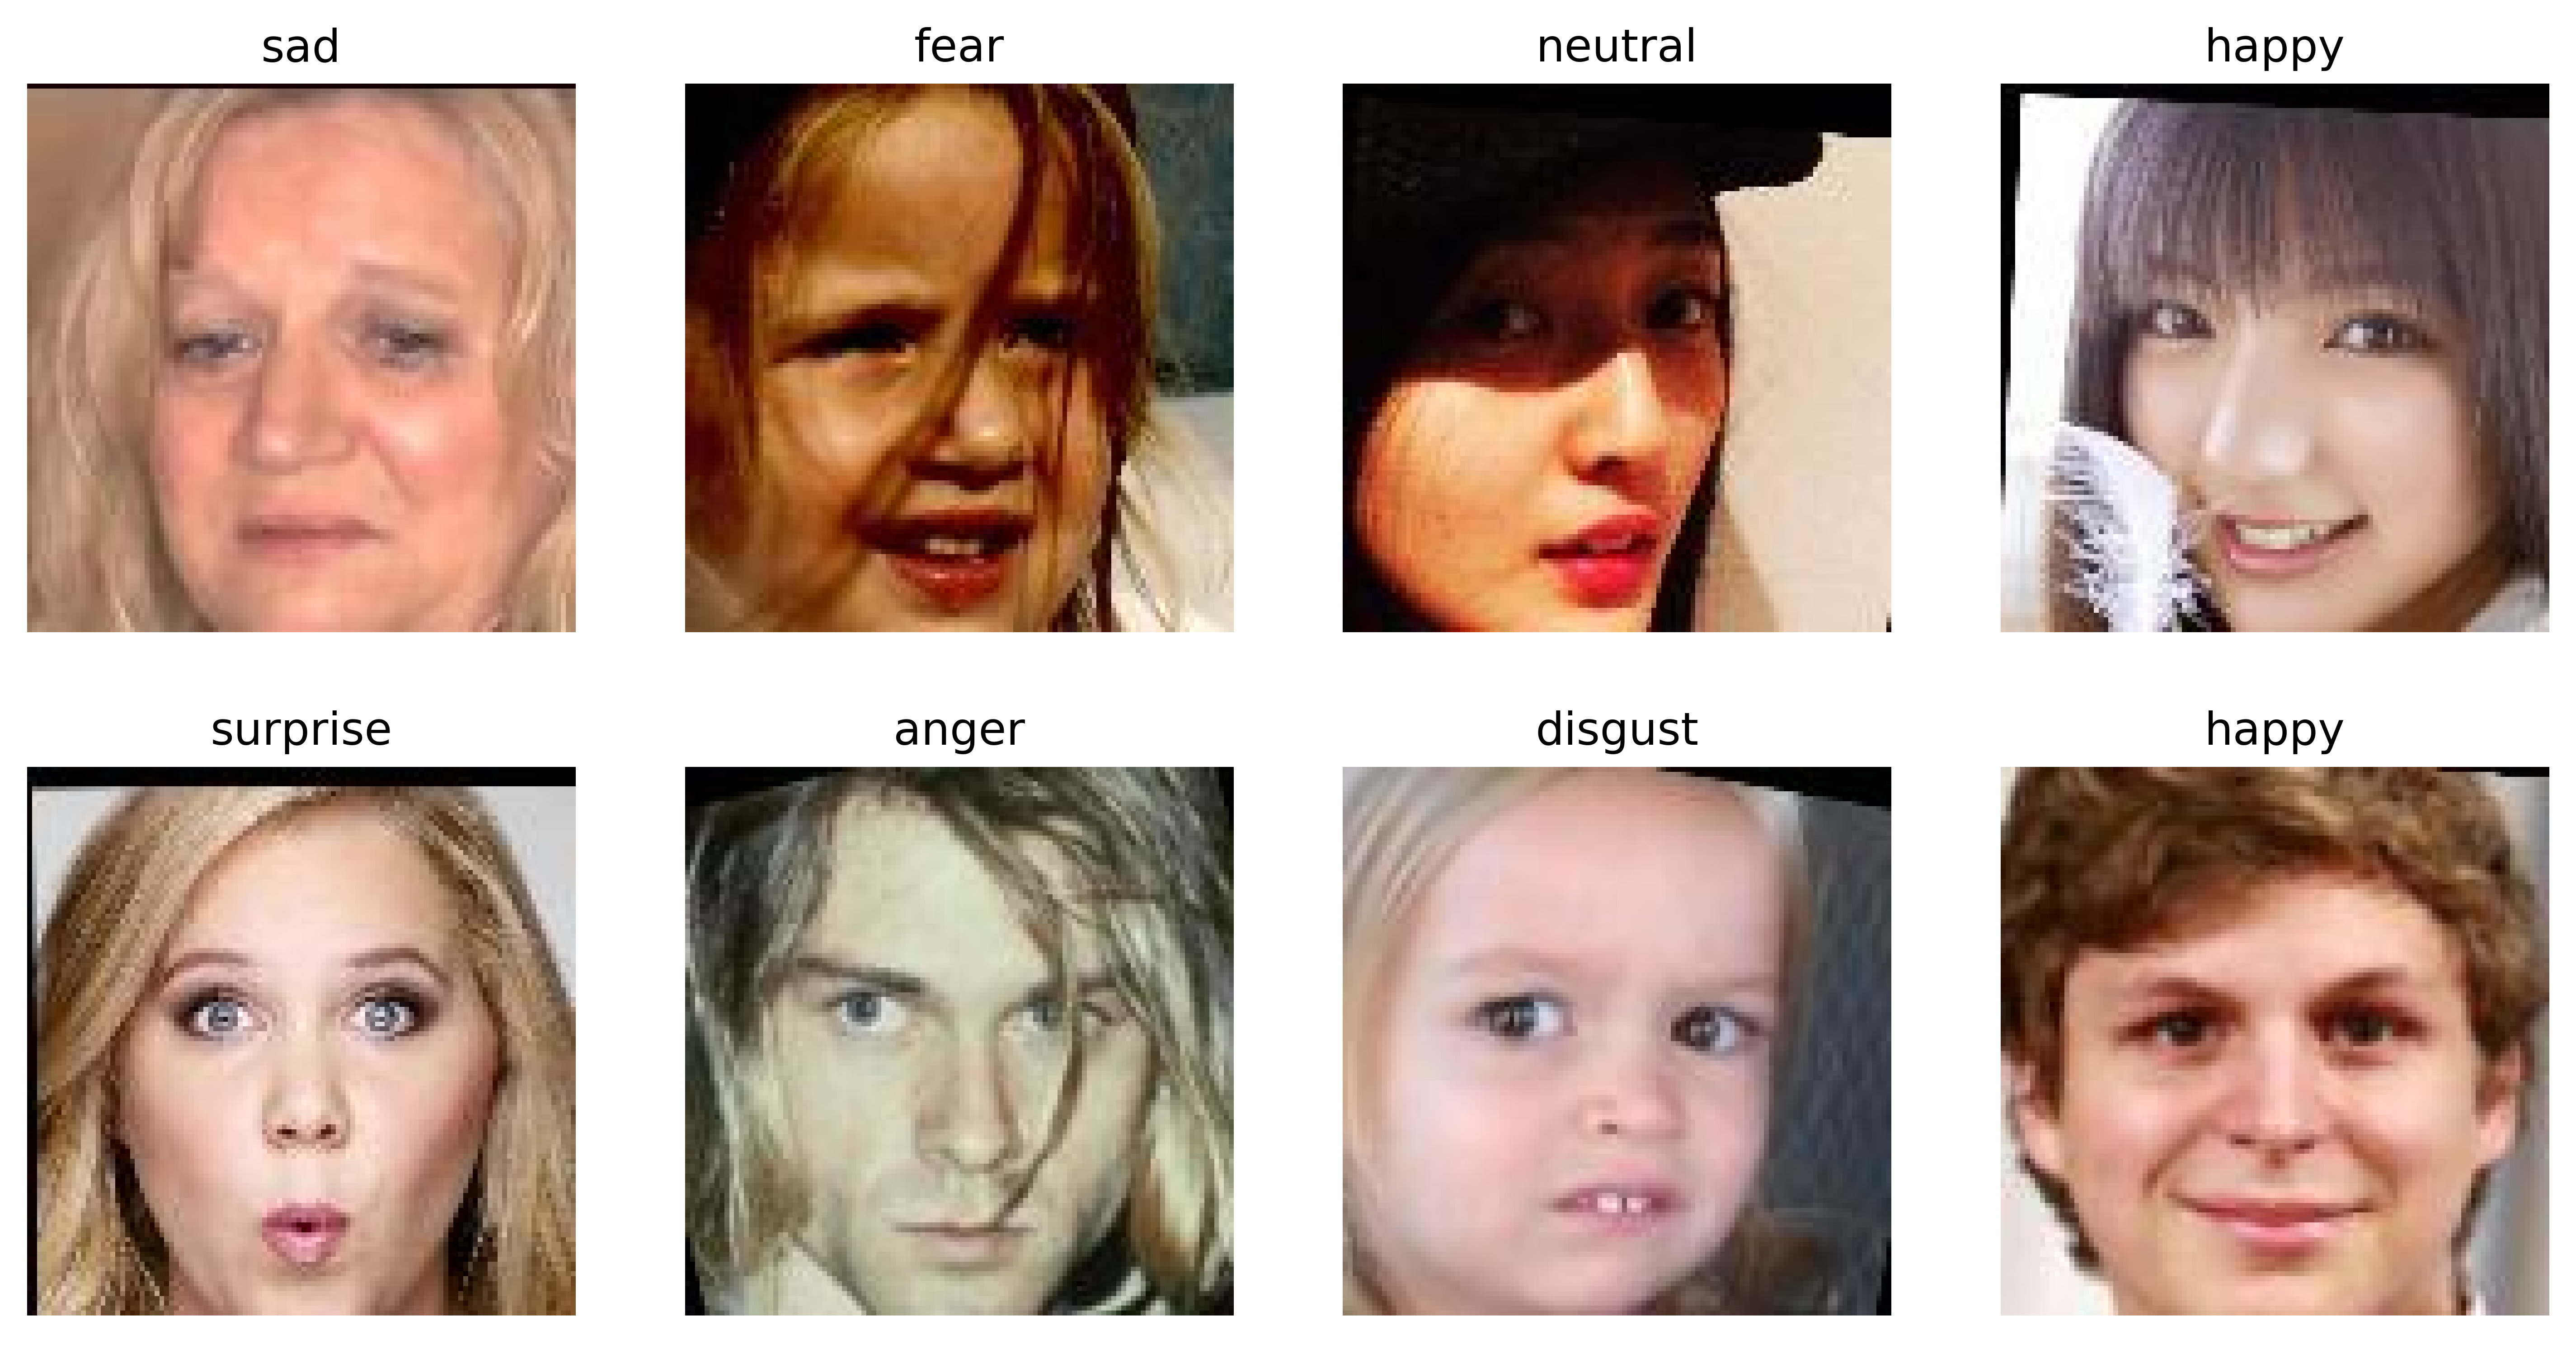

In [12]:
plt.figure(figsize = (12, 6), dpi = 600)
plt.axis('off')
chosen_emotions = []
for i in range(8):
    idx = np.random.randint(low = 0, high = len(labels_df))
    label_translated = labels_df['translated'][idx]

    while label_translated in chosen_emotions:
       idx = np.random.randint(low = 0, high = len(labels_df))
       label_translated = labels_df['translated'][idx]

       if len(chosen_emotions) >= 7:
           break
    chosen_emotions.append(label_translated)
     
    image_name = labels_df['filename'][idx]
    image = plt.imread(os.path.join(output_dir, 'Images', image_name))

    plt.subplot(2, 4, i+1)
    plt.imshow(image)
    plt.title(label_translated)
    plt.axis('off')
plt.savefig(
    os.path.join('data', 'figures', 'Emotion Recognition', 'AffectNet', 'Sample images from AffectNet')
)
plt.show()

In [18]:
labels = labels_df['label'][labels_df['split'] == 'test']
soft_labels = labels_df[['0', '1', '2', '3', '4', '5', '6']][labels_df['split'] == 'test']
preds = np.argmax(soft_labels, axis = 1)

In [19]:
sum(labels == preds) / len(labels)

0.6554285714285715